# An optimal-transport start for shaped potentials

**Question:** Does an optimal-transport start beat the published method for shaped potentials, slmsuite's MRAF run on the same target, at the same mixing and the same number of iterations, and where does the gain come from?

- **Level:** 3, Comparison with published methods
- **Prerequisites:** notebook 03 of this topic
- **Reading time:** about 55 minutes

## Objectives

The previous notebook left MRAF needing a smooth start, and at the mixing of 0.4 used here it leaves the disc with an error of 0.1451 after 30 iterations (cell 8 below measures it). A recent line of work (Swan et al. 2024, https://arxiv.org/abs/2408.17025) starts MRAF from the phase that an optimal-transport map would give, the phase that carries the Gaussian beam to the target shape with the least displacement of light. DinHot implements it as M18, with the separable Sinkhorn solver of Torchylo et al. (2025). You will build that start, measure what it is on its own, run MRAF from it and from the Fresnel start, then run slmsuite 0.5.0's MRAF on the same target and compare, including the case in which slmsuite is handed the optimal-transport phase. The last test shows where the gain comes from.

## Setup

The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows). The packages this notebook uses, with their exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2 slmsuite==0.5.0
```

DinHot publishes no package of its own: its methods live in `data-pipeline/pipeline/` and the notebook imports them by their path. The next cell imports the tools, prints their versions and puts the pipeline on the path.

In [1]:
# the tools and their versions, the pipeline's modules by path, and the pinned reference implementation
import importlib.metadata as md
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.build import setup_of, target_of
from pipeline.core import score
from pipeline.io.contract import read_cases
from pipeline.model.holo.core import forward, geometry
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.methods.baseline import m08_mraf
from pipeline.model.holo.methods.optim import m18_ot_mraf
import slmsuite
from slmsuite.holography.algorithms import Hologram

slmsuite.configure_logging(None)  # no console log inside the outputs

for name in ("numpy", "matplotlib", "slmsuite"):
    print(name, md.version(name))


def shape_numbers(phi, target, setup):
    """The product's two numbers of a shape: the error (``score.signal_error_pct`` over 100) and the power
    fraction in the signal region."""
    field = forward.fft_focal_field(phi, setup)
    error = score.signal_error_pct(field, target, setup) / 100.0
    return error, np.sum(np.abs(field[target.mask]) ** 2) / setup.n_pix**2

numpy 2.4.6
matplotlib 3.11.2
slmsuite 0.5.0


## Data

- Owner: this repository, https://github.com/fsantibanezleal/CEFOP_DinHot; slmsuite 0.5.0 is an open-source library for holography on SLMs under the MIT licence (https://pypi.org/project/slmsuite/).
- Licence class: synthetic case written by the product, no third-party dataset; the reference implementation is used as a library under its own licence.
- File read: `data/examples/cases.json`, case C04, a disc of 15 um radius on the 256 by 256 pixel SLM; its device (8 bits, pixel crosstalk) is not used, since neither M08, M18 nor slmsuite's MRAF models it.

In [2]:
# case C04: a disc of 15 um radius, shaped on the 256 x 256 pixel SLM; the device of the case is not used here
records = {rec["case_id"]: rec for rec in read_cases(ROOT / "data" / "examples" / "cases.json")}
rec = records["C04_disc_crosstalk"]
setup = setup_of(rec)
target = target_of(rec)
seed = rec["seed"]
mixing = 0.4
print(f"disc of {int((target.amplitude > 0).sum())} bins, signal region {int(target.mask.sum())} bins")
print(f"mixing {mixing}")

disc of 2861 bins, signal region 3389 bins
mixing 0.4


## Method

Both methods iterate MRAF (Pasienski and DeMarco 2008, https://doi.org/10.1364/OE.16.002176): inside the signal region the focal amplitude is forced to $mT$, outside it keeps $(1-m)$ of what the hologram made. They differ in the phase they start from. M08 starts from a Fresnel lens phase. M18 starts from the optimal-transport phase. Under the stationary-phase approximation the SLM phase $\phi$ satisfies a Monge-Ampere equation, $G^2(\nabla\phi)\det\nabla^2\phi = g^2$, with $g^2$ the intensity of the input beam and $G^2$ that of the target; its solution is the quadratic-cost optimal-transport map between the two, and $\phi$ is the integral of that map (Swan et al. 2024). The map is computed by entropic regularization, the Sinkhorn iteration, and Torchylo et al. (2025, https://arxiv.org/abs/2512.19072) show that for a separable cost the kernel factorizes, so the plan costs $O(N)$ memory and each update is a pair of small matrix products. The product integrates the map with a least-squares Poisson solve. Swan et al. report, on six targets, errors of 1.5 to 3.9 percent for MRAF with efficiency 18 to 45 percent and 0.17 to 0.96 percent with efficiency 53 to 85 percent from the transport start. The cells below measure the same quantities on one target.

The reference of this notebook is the product's MRAF. The cell runs M08 for 30 iterations at the mixing 0.4 that M18 uses by default (the upper end of the 0.30 to 0.40 range that Pasienski and DeMarco 2008 give for MRAF, the product's choice, recorded in the M18 design record) and at two lower mixings, 0.2 and 0.3, and prints the error of the profile and the power fraction in the signal region, as defined in the previous notebook.

In [3]:
# the product's MRAF (M08, a Fresnel-lens start): the mixing 0.4 of M18 and two lower mixings, 30 iterations
budget = Budget(rec["budget"]["iterations"])
mraf_runs = {}
for m in (0.2, 0.3, 0.4):
    mraf_runs[m] = m08_mraf.run(setup, target, budget=budget, rng=Rng(seed), mixing=m)
    err, eff = shape_numbers(mraf_runs[m].phi, target, setup)
    print(f"M08, m = {m}: error = {err:.4f}, signal power fraction = {eff:.4f}")
res_mraf = mraf_runs[mixing]

M08, m = 0.2: error = 0.0272, signal power fraction = 0.0621
M08, m = 0.3: error = 0.0517, signal power fraction = 0.1719
M08, m = 0.4: error = 0.1451, signal power fraction = 0.3928


Now the start. The cell computes the optimal-transport phase alone, with the product's function, and scores it as if it were a hologram. It prints the residual of the Sinkhorn solution, which is how far the plan is from having the beam as its marginal, and the width of the kernel in bins.

In [4]:
# the optimal-transport start of M18 alone: the Sinkhorn plan, its barycentric map, integrated to a phase
phi_ot, info = m18_ot_mraf.ot_phase(setup, target.amplitude, target.mask)
err, eff = shape_numbers(phi_ot, target, setup)
print(f"OT phase alone, no MRAF iteration: error = {err:.4f}, signal power fraction = {eff:.4f}")
print(f"Sinkhorn residual {info['residual']:.2e}, kernel width {info['sigma_bins']:.2f} bins")

OT phase alone, no MRAF iteration: error = 0.4294, signal power fraction = 0.9933
Sinkhorn residual 1.73e-16, kernel width 16.19 bins


Then M18: the start followed by 30 iterations of MRAF at the same mixing. To see how the two methods move, the cell also runs MRAF for 1, 3 and 10 iterations from the Fresnel start and from the transport phase and prints the error of each.

In [5]:
# M18: the same OT start followed by 30 MRAF iterations at the same mixing, and a series of shorter budgets
res_ot = m18_ot_mraf.run(setup, target, budget=budget, rng=Rng(seed), mix=mixing)
err, eff = shape_numbers(res_ot.phi, target, setup)
print(f"M18, m = {mixing}: error = {err:.4f}, signal power fraction = {eff:.4f}")
steps = (1, 3, 10, 30)
curve_mraf = [shape_numbers(m08_mraf.run(setup, target, budget=Budget(k), rng=Rng(seed), mixing=mixing).phi,
                            target, setup)[0] for k in steps]
curve_ot = [shape_numbers(m18_ot_mraf.run(setup, target, budget=Budget(k), rng=Rng(seed), mix=mixing, init=phi_ot).phi,
                          target, setup)[0] for k in steps]
print(f"MRAF iterations {steps}")
print("M08", np.round(curve_mraf, 4))
print("M18", np.round(curve_ot, 4))

M18, m = 0.4: error = 0.0275, signal power fraction = 0.4446
MRAF iterations (1, 3, 10, 30)
M08 [0.2334 0.2737 0.1862 0.1451]
M18 [0.3552 0.3422 0.136  0.0275]


## Comparison

slmsuite is an open-source Python library for computing holograms on SLMs, and its MRAF is the reference for shaped potentials that users of the field run. In its `Hologram`, the target amplitude is an array on the padded Fourier grid, and a pixel set to NaN is a noise region; the attenuation of the noise region is the flag `mraf_factor`. With the notation of the Method section, slmsuite keeps the signal amplitude and multiplies the noise region by a factor, which is DinHot's $m$ and $(1-m)$ divided by $m$: the factor of this notebook is 1.5. Everything else is slmsuite's default, the weighting included, so the comparison is of the library as a user would run it.

The first slmsuite cell runs its MRAF on the C04 disc, with the same signal region, the same normalized Gaussian beam, the same factor, 30 iterations, and a choice of starting phase through the `phase` argument: first the Fresnel phase of M08, then the optimal-transport phase of M18. It prints the same two numbers.

In [6]:
# slmsuite's MRAF on the same target: noise region = NaN, attenuation factor (1 - m) / m, the same Fresnel start as M08
x, y = geometry.slm_grid(setup)
fresnel = 2 * np.pi * 20.0 * (x**2 + y**2) / (setup.n_pix * setup.pitch_m / 2) ** 2
goal = np.where(target.mask, target.amplitude, np.nan)
beam = geometry.input_amplitude(setup)
factor = (1 - mixing) / mixing
starts = {"slmsuite, Fresnel start": fresnel, "slmsuite, OT start": phi_ot}
reference = {}
for label, start in starts.items():
    holo = Hologram(goal.copy(), slm_shape=(setup.n_pix, setup.n_pix), amp=beam, phase=start.copy())
    holo.optimize(method="GS", maxiter=30, verbose=False, mraf_factor=factor)
    reference[label] = np.array(holo.get_phase(), dtype=float)
    err, eff = shape_numbers(reference[label], target, setup)
    print(f"{label}: error = {err:.4f}, signal power fraction = {eff:.4f}")

slmsuite, Fresnel start: error = 0.1451, signal power fraction = 0.3928
slmsuite, OT start: error = 0.0275, signal power fraction = 0.4446


A user who does not precondition gets slmsuite's own start, a random phase. The cell runs that case, seeded, and prints the same two numbers.

In [7]:
# and slmsuite from its own default start, a random phase, which is what a user gets without preconditioning
np.random.seed(seed)
holo = Hologram(goal.copy(), slm_shape=(setup.n_pix, setup.n_pix), amp=beam)
holo.optimize(method="GS", maxiter=30, verbose=False, mraf_factor=factor)
reference["slmsuite, random start"] = np.array(holo.get_phase(), dtype=float)
err, eff = shape_numbers(reference["slmsuite, random start"], target, setup)
print(f"slmsuite, random start: error = {err:.4f}, signal power fraction = {eff:.4f}")

slmsuite, random start: error = 0.2940, signal power fraction = 0.4236


All the runs on one table: the two product methods and the three slmsuite runs.

In [8]:
# every run of the notebook on one table: the same target, the same mixing, 30 iterations
finals = {"M08 (Fresnel start)": res_mraf.phi, "M18 (OT start)": res_ot.phi, **reference}
for label, phi in finals.items():
    err, eff = shape_numbers(phi, target, setup)
    print(f"{label:26s} error = {err:.4f}   signal power fraction = {eff:.4f}   outside it = {1 - eff:.4f}")

M08 (Fresnel start)        error = 0.1451   signal power fraction = 0.3928   outside it = 0.6072
M18 (OT start)             error = 0.0275   signal power fraction = 0.4446   outside it = 0.5554
slmsuite, Fresnel start    error = 0.1451   signal power fraction = 0.3928   outside it = 0.6072
slmsuite, OT start         error = 0.0275   signal power fraction = 0.4446   outside it = 0.5554
slmsuite, random start     error = 0.2940   signal power fraction = 0.4236   outside it = 0.5764


The first figure plots the error of the product's two methods against the number of MRAF iterations on logarithmic axes, for the Fresnel start and for the optimal-transport start.

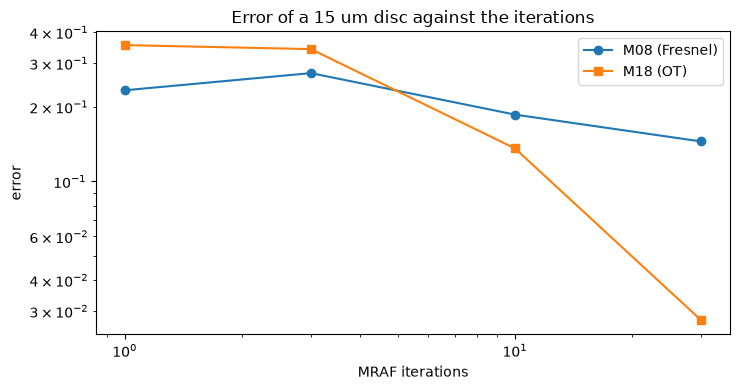

In [9]:
# the error of the shape against the number of MRAF iterations, M08 and M18, log axes
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.loglog(steps, curve_mraf, "o-", label="M08 (Fresnel)")
ax.loglog(steps, curve_ot, "s-", label="M18 (OT)")
ax.set_xlabel("MRAF iterations")
ax.set_ylabel("error")
ax.set_title("Error of a 15 um disc against the iterations")
ax.legend()
fig.tight_layout()
plt.show()

At one and three iterations the Fresnel start is ahead: 0.2334 and 0.2737 against 0.3552 and 0.3422, because the transport phase alone has an error of 0.4294 and puts 0.9933 of the power in the signal region, like Gerchberg-Saxton, so MRAF has to drain it first. By 10 iterations the transport start is ahead, 0.1360 against 0.1862, and at 30 it is five times lower, 0.0275 against 0.1451. The Fresnel curve is not monotone: it rises from 0.2334 at one iteration to 0.2737 at three. The figure covers 30 iterations; it does not say where either curve ends, and a run to convergence would be needed for that.

The second figure draws the focal power along the row through the axis for the five runs, each scaled to the target level inside the disc, with the target as a dashed black line. The product's two methods are drawn wide and pale, slmsuite's runs thin and dashed on top of them.

M08 (Fresnel start): inside the disc, from 0.61 to 1.46 of the target level
M18 (OT start): inside the disc, from 0.86 to 1.19 of the target level
slmsuite, Fresnel start: inside the disc, from 0.61 to 1.46 of the target level
slmsuite, OT start: inside the disc, from 0.86 to 1.19 of the target level
slmsuite, random start: inside the disc, from 0.26 to 1.44 of the target level


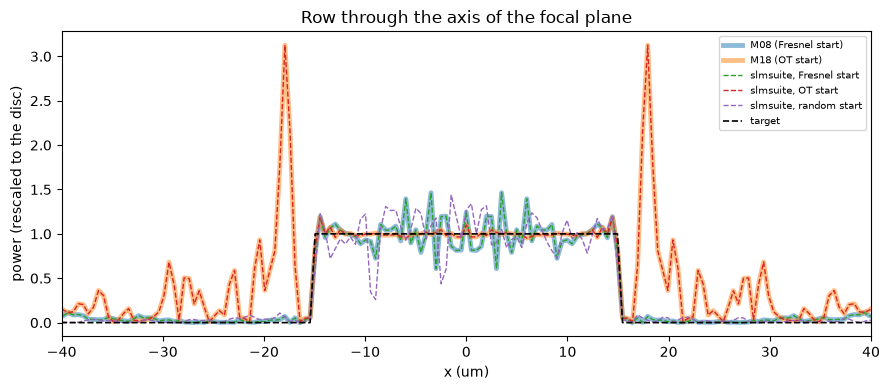

In [10]:
# the focal power of the disc along the row through the axis, each run divided by the power wanted inside the disc
c = setup.n_fft // 2
fig, ax = plt.subplots(figsize=(9, 4))
axis = (np.arange(setup.n_fft) - c) * geometry.focal_bin_m(setup) * 1e6
for label, phi in finals.items():
    row = np.abs(forward.fft_focal_field(phi, setup)[c]) ** 2
    scale = (target.amplitude[c] ** 2).sum() / row[target.amplitude[c] > 0].sum()
    product = label.startswith("M")
    style = dict(ls="-", lw=3.5, alpha=0.5) if product else dict(ls="--", lw=1, alpha=1.0)
    ax.plot(axis, row * scale, label=label, **style)
    inside = target.amplitude[c] > 0
    ratio = (row * scale)[inside] / target.amplitude[c][inside] ** 2
    print(f"{label}: inside the disc, from {ratio.min():.2f} to {ratio.max():.2f} of the target level")
ax.plot(axis, target.amplitude[c] ** 2, "k--", lw=1.2, label="target")
ax.set_xlim(-40, 40)
ax.set_xlabel("x (um)")
ax.set_ylabel("power (rescaled to the disc)")
ax.set_title("Row through the axis of the focal plane")
ax.legend(fontsize=7, loc="upper right")
fig.tight_layout()
plt.show()

The wide and the thin lines of the same start lie on each other: slmsuite's MRAF from the Fresnel phase is M08, and slmsuite's MRAF from the transport phase is M18, to the printed precision. Inside the disc the Fresnel start ripples between 0.61 and 1.46 of the target level and the random start dips to 0.26 of it, while the transport start stays between 0.86 and 1.19 of it (the printed ranges). Outside the disc the transport start puts spikes, up to three times the target level, on both sides of the edge near 18 um, and smaller ones further out: that is the noise region at work, holding about 55 percent of the light, and a potential that has those spikes is not the potential of the disc. The error and the power fraction of this notebook do not penalize them, and the figure shows one row of a two-dimensional pattern.

## Results

**Answer:** At the same mixing and the same number of iterations, yes: from the optimal-transport start the disc error is 0.0275 with 0.4446 of the power in the signal region, against 0.1451 with 0.3928 for MRAF from the Fresnel start, five times lower and with more power, and against 0.2940 for slmsuite's MRAF from its own random start. M08 reaches an error as low only at a lower mixing: 0.0272 at $m = 0.2$, but with 0.0621 of the power, seven times less. The gain comes from the start and not from the code: slmsuite, handed the transport phase, gives 0.0275 and 0.4446, the numbers of M18, and handed the Fresnel phase it gives 0.1451 and 0.3928, the numbers of M08. The limits are those of one target: the error 0.0275 is 2.75 percent, above the 0.17 to 0.96 percent that Swan et al. report on other targets; the first iterations are worse than the Fresnel start's; and 0.5554 of the power is outside the signal region.

## Summary

An optimal-transport start is an inexpensive way to buy accuracy and efficiency together in MRAF on this disc: the start alone is a poor hologram, and the MRAF iterations then turn it into a better one than the Fresnel and the random starts reach in the same budget. The product's two MRAF methods agree with slmsuite's to four digits when they are given the same start, which supports the implementation of both. What the notebook does not show is whether the gain holds on a ring, a line or a Laguerre-Gauss target, whether the spikes next to the edge are acceptable for a given experiment, or whether the Sinkhorn solve is worth its time on a small SLM.

## References

- Swan, Torchylo, Van de Graaff, Rudolph and Hogan, arXiv 2408.17025 (2024), the optimal-transport initialization of Gerchberg-Saxton and MRAF, https://arxiv.org/abs/2408.17025.
- Torchylo, Swan, Tellez and Hogan, arXiv 2512.19072 (2025), the separable Sinkhorn form with linear memory, https://arxiv.org/abs/2512.19072.
- Pasienski and DeMarco, "A high-accuracy algorithm for designing arbitrary holographic atom traps", Optics Express 16, 2176 (2008), https://doi.org/10.1364/OE.16.002176.
- slmsuite 0.5.0 (MIT), https://pypi.org/pypi/slmsuite/json and https://pypi.org/project/slmsuite/.